In [149]:
# Step 1. libraries and project settings (in-class w12 Setup & Assignment 8)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col   # [AI] needed to display side-by-side regression tables
import wrds

# Connect to WRDS
conn = wrds.Connection()

# Settings for Project 3 (SIC 28 vs Peer SIC 61)
SIC        = "28"            # client industry: Chemicals & Pharmaceuticals (Pfizer)
PEER_SIC   = "61"            # peer industry: Non-Depository Credit Institutions
QTR_START  = "2021-01-01"    # sample period start (announcement date rdq)
QTR_END    = "2024-12-31"    # sample period end (announcement date rdq)
PULL_START = "2019-06-01"    # pull earlier quarters to compute 4-quarter-ago EPS
RET_START  = "2020-12-15"    # start daily returns early enough for Day -1
RET_END    = "2025-01-15"    # end daily returns late enough for Day +1
MIN_PRC    = 5               # Rule 4: prior quarter stock price >= $5
MAX_SUE    = 1               # Rule 5: |SUE| <= 1
LABELS     = ["Low", "Middle", "High"]

Loading library list...
Done


In [150]:
# Step 2. Load shared link file and daily market index (in-class w12 Part 1 & From Day 0 to CAR)
link_all = pd.read_csv("ccm_link.csv", dtype=str)
link_all["gvkey"]     = link_all["gvkey"].str.zfill(6)
link_all["permno"]    = pd.to_numeric(link_all["permno"]).astype(int)
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# Pull daily value-weighted market returns (crsp.dsi) once for all industries
dsi = conn.raw_sql(f"""
    select date, vwretd
    from crsp.dsi
    where date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])
dsi["vwretd"] = pd.to_numeric(dsi["vwretd"], errors="coerce").astype("float64")

# Sort market dates and assign sequential trading-day numbers 1, 2, 3... (From Day 0 to CAR)
dsi = dsi.sort_values("date").reset_index(drop=True)
dsi["tday"] = dsi.index + 1

print("Link file rows:", len(link_all), "| Market trading days:", len(dsi))

Link file rows: 2667 | Market trading days: 1017


In [151]:
# Step 3. Define the Industry class so both SIC 28 and SIC 61 use identical rules (in-class w12 Part 5a)
class Industry:
    """Builds the quarterly SUE & 3-day CAR dataset for one industry and runs all analyses."""

    def __init__(self, sic, name):
        self.sic = sic                  # store 2-digit SIC code
        self.name = name                # store industry name for labels and charts
        self.events = None              # will hold the final cleaned DataFrame
        self.sample_counts = None       # [AI] will store row counts for Rules 1-6

    def build(self):
        # 1. Filter link file to this industry's SIC
        link = link_all[link_all["sic2"] == self.sic].reset_index(drop=True)
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"

        # 2. Pull quarterly fundamentals from comp.fundq (Project 2 Step 2)
        fq = conn.raw_sql(f"""
            select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
            from comp.fundq
            where gvkey in ({gv})
              and datadate between '{PULL_START}' and '{QTR_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate", "rdq"])

        # Convert numeric columns to standard float64
        fq["epspxq"] = pd.to_numeric(fq["epspxq"], errors="coerce").astype("float64")
        fq["prccq"]  = pd.to_numeric(fq["prccq"], errors="coerce").astype("float64")
        fq["fyearq"] = pd.to_numeric(fq["fyearq"], errors="coerce")
        fq["fqtr"]   = pd.to_numeric(fq["fqtr"], errors="coerce")
        fq = fq.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "datadate"], keep="last").reset_index(drop=True)
        r_pull = len(fq)

        # 3. Merge 1: Attach permno and keep only active link dates (Project 2 Step 3)
        panel = fq.merge(link[["gvkey", "permno", "ticker", "comnam", "linkdt", "linkenddt"]], on="gvkey", how="inner")
        valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
        panel = panel[valid].drop_duplicates(["gvkey", "datadate"], keep="last")
        panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)
        r_m1 = len(panel)

        # 4. Merge 2: Compute quarter number and attach 4-quarter-ago EPS & 1-quarter-ago price (Project 2 Step 4)
        panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]
        panel = panel.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "qnum"], keep="last").reset_index(drop=True)

        eps4 = panel[["gvkey", "qnum", "epspxq"]].copy()
        eps4["qnum"] = eps4["qnum"] + 4
        eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})

        prc1 = panel[["gvkey", "qnum", "prccq"]].copy()
        prc1["qnum"] = prc1["qnum"] + 1
        prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

        panel = panel.merge(eps4, on=["gvkey", "qnum"], how="left", validate="one_to_one")
        panel = panel.merge(prc1, on=["gvkey", "qnum"], how="left", validate="one_to_one")
        panel["sue"] = (panel["epspxq"] - panel["eps_4q_ago"]) / panel["prc_1q_ago"].abs()

        # 5. Apply Rules 1 to 5 in the exact order of Project 2 Check 1
        d1 = panel[panel["rdq"].notna()]                                                     # Rule 1: rdq known
        d2 = d1[(d1["rdq"] >= QTR_START) & (d1["rdq"] <= QTR_END)]                           # Rule 2: rdq in 2021-2024
        d3 = d2[d2["sue"].notna()]                                                           # Rule 3: SUE computed
        d4 = d3[d3["prc_1q_ago"].abs() >= MIN_PRC]                                           # Rule 4: lagged price >= $5
        events = d4[d4["sue"].abs() <= MAX_SUE].reset_index(drop=True)                       # Rule 5: |SUE| <= 1

        # 6. Merge 3: Pull daily stock returns (crsp.dsf) and attach market return & tday (Project 2 Step 6)
        permnos = ",".join(events["permno"].astype(str).unique())
        dsf = conn.raw_sql(f"""
            select permno, date, ret
            from crsp.dsf
            where permno in ({permnos})
              and date between '{RET_START}' and '{RET_END}'
        """, date_cols=["date"])
        dsf["permno"] = dsf["permno"].astype(int)
        dsf["ret"]    = pd.to_numeric(dsf["ret"], errors="coerce").astype("float64")

        daily = dsf.merge(dsi[["date", "vwretd", "tday"]], on="date", how="left")
        daily["ar"] = daily["ret"] - daily["vwretd"]

        # 7. Find Day 0 (first trading day on or after rdq) and Merge 4 for [-1, 0, +1] window (Project 2 Step 7)
        events["event_id"] = events.index
        pairs = events[["event_id", "rdq"]].merge(dsi[["date", "tday"]], how="cross")
        pairs = pairs[pairs["date"] >= pairs["rdq"]]
        day0 = pairs.groupby("event_id")["tday"].min().reset_index()
        day0 = day0.rename(columns={"tday": "day0"})
        events = events.merge(day0, on="event_id", how="left")

        offsets = pd.DataFrame({"offset": [-1, 0, 1]})
        window = events[["event_id", "permno", "day0"]].merge(offsets, how="cross")
        window["tday"] = window["day0"] + window["offset"]
        window = window.merge(daily[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")

        # 8. Sum AR into 3-day CAR and apply Rule 6 (all 3 trading days found) (Project 2 Step 8)
        car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
        car = car.rename(columns={"sum": "car", "count": "days_found"})
        events = events.merge(car, on="event_id", how="left")
        events["days_found"] = events["days_found"].fillna(0)
        final = events[events["days_found"] == 3].reset_index(drop=True)

        # 9. Assign 3 equal SUE groups, winsorize CAR at 1%/99%, and create regression variables (in-class w12 Part 4 & 5a)
        final["sue_group"] = pd.qcut(final["sue"].rank(method="first"), 3, labels=LABELS)
        lo, hi = final["car"].quantile([0.01, 0.99])
        final["car_w"] = final["car"].clip(lo, hi)
        final["fyearq"] = final["fyearq"].astype(int)
        final["loss"] = (final["epspxq"] < 0).astype(int)

        # Save row counts across steps for sample construction verification
        self.sample_counts = {
            "Pulled (fundq)": r_pull,
            "Merge 1 (link)": r_m1,
            "Rule 1 (rdq known)": len(d1),
            "Rule 2 (2021-2024)": len(d2),
            "Rule 3 (SUE valid)": len(d3),
            "Rule 4 (Prc >= $5)": len(d4),
            "Rule 5 (|SUE| <= 1)": len(events),
            "Rule 6 (3 days CAR)": len(final)
        }
        self.events = final
        print(f"{self.name} (SIC {self.sic}): {len(final)} announcements, {final['gvkey'].nunique()} companies")
        return self

    # Method: Group summary table with mean CAR and 95% CI (in-class w12 Part 5a)
    def group_table(self):
        t = self.events.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
        t["se"] = t["sd"] / np.sqrt(t["n"])
        t["ci95"] = 1.96 * t["se"]
        return t

    # Method: Welch's t-test comparing High vs Low SUE groups (in-class w12 Part 5a)
    def ttest(self):
        high = self.events.loc[self.events["sue_group"] == "High", "car"]
        low  = self.events.loc[self.events["sue_group"] == "Low",  "car"]
        t_stat, p_val = stats.ttest_ind(high, low, equal_var=False)
        gap_pp = (high.mean() - low.mean()) * 100
        return {"High - Low (pp)": gap_pp, "t": t_stat, "p (t-test)": p_val}

    # Method: Base OLS regression CAR = a + b * SUE (original & winsorized) (in-class w12 Part 4b & 5a)
    def regression(self):
        m_orig = smf.ols("car ~ sue", data=self.events).fit()
        m_win  = smf.ols("car_w ~ sue", data=self.events).fit()
        return {
            "b (orig)": m_orig.params["sue"],
            "p (orig)": m_orig.pvalues["sue"],
            "R2 (orig)": m_orig.rsquared,
            "b (win)": m_win.params["sue"],
            "p (win)": m_win.pvalues["sue"],
            "R2 (win)": m_win.rsquared
        }

    # [AI] Method: Run the 3 recommended regression models with firm-clustered SEs (in-class w12 Part 4b cell 37)
    def regression_models(self):
        cl = dict(cov_type="cluster", cov_kwds={"groups": self.events["gvkey"]})
        m1 = smf.ols("car_w ~ sue", data=self.events).fit(**cl)
        m2 = smf.ols("car_w ~ sue + C(fyearq)", data=self.events).fit(**cl)
        m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=self.events).fit(**cl)
        return [m1, m2, m3]

    # Method: Single-row summary combining sample size, t-test, and regression (in-class w12 Part 5a)
    def summary(self):
        row = {
            "Industry": self.name,
            "SIC": self.sic,
            "n": len(self.events),
            "Companies": self.events["gvkey"].nunique()
        }
        row.update(self.ttest())
        row.update(self.regression())
        return row

In [152]:
# Step 4. Build both SIC 28 (Client Industry) and SIC 61 (Peer Industry) using the same class (in-class w12 Part 5b)
mine = Industry(SIC, "Chemicals & Pharma").build()
peer = Industry(PEER_SIC, "Non-Depository Credit").build()

# [AI] Display side-by-side sample construction counts to verify identical filtering rules
funnel_compare = pd.DataFrame({
    "SIC 28 (Chemicals & Pharma)": mine.sample_counts,
    "SIC 61 (Non-Depository Credit)": peer.sample_counts
})
print("\nSample construction comparison:")
display(funnel_compare)

Chemicals & Pharma (SIC 28): 2577 announcements, 219 companies
Non-Depository Credit (SIC 61): 530 announcements, 37 companies

Sample construction comparison:


,SIC 28 (Chemicals & Pharma),SIC 61 (Non-Depository Credit)
Pulled (fundq),5998,1007
Merge 1 (link),5800,917
Rule 1 (rdq known),5738,906
Rule 2 (2021-2024),3990,647
Rule 3 (SUE valid),3894,618
Rule 4 (Prc >= $5),2591,530
Rule 5 (|SUE| <= 1),2584,530
Rule 6 (3 days CAR),2577,530


In [153]:
# Step 5. Compare t-test and base regression results across both industries (in-class w12 Part 5c)
compare = pd.DataFrame([mine.summary(), peer.summary()]).set_index("Industry")
display(compare.round(4))

# Print plain-word t-test readout for each industry (in-class w12 Part 3)
for ind in [mine, peer]:
    res = ind.ttest()
    print(f"{ind.name} (SIC {ind.sic}): High - Low = {res['High - Low (pp)']:.2f} pp | "
          f"t = {res['t']:.2f} | p = {res['p (t-test)']:.4f}")

,SIC,n,Companies,High - Low (pp),t,p (t-test),b (orig),p (orig),R2 (orig),b (win),p (win),R2 (win)
Industry,,,,,,,,,,,,
Chemicals & Pharma,28,2577,219,3.0494,6.2800,0.0,0.1105,0.0,0.0066,0.0963,0.0001,0.0059
Non-Depository Credit,61,530,37,5.8757,6.7133,0.0,0.2491,0.0,0.0477,0.2359,0.0000,0.0502


Chemicals & Pharma (SIC 28): High - Low = 3.05 pp | t = 6.28 | p = 0.0000
Non-Depository Credit (SIC 61): High - Low = 5.88 pp | t = 6.71 | p = 0.0000


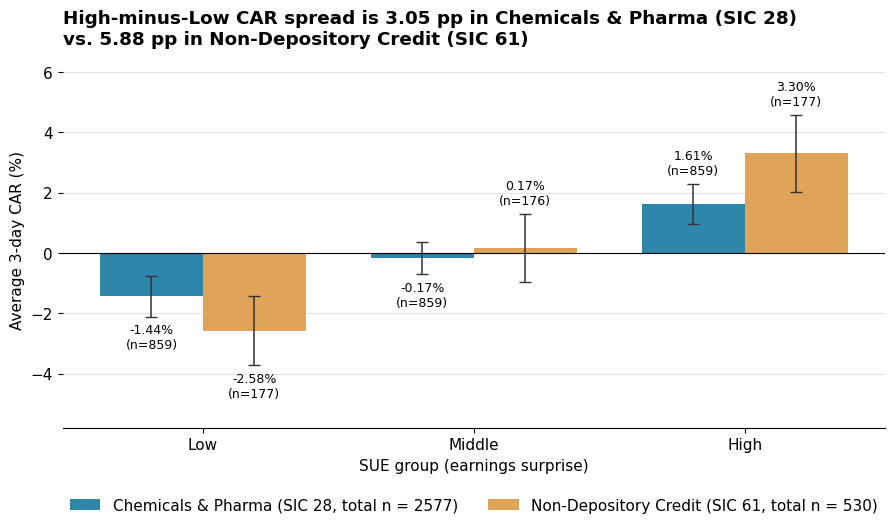

In [154]:
# Step 6. Figure 1: Side-by-side bar chart of average CAR by SUE group with 95% CI and n (in-class w12 Part 2c & 5d)
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False
})

industries = [mine, peer]
colors = ["#2E86AB", "#E0A458"]   # consistent industry colors across all figures

fig, ax = plt.subplots(figsize=(9.5, 5.5))
x = np.arange(len(LABELS))
width = 0.38

for j, ind in enumerate(industries):
    t = ind.group_table()
    means = t["mean"] * 100
    cis   = t["ci95"] * 100
    xpos  = x + (j - 0.5) * width

    # Draw bars with 95% confidence interval error bars
    ax.bar(xpos, means, width, yerr=cis, capsize=4, color=colors[j],
           label=f"{ind.name} (SIC {ind.sic}, total n = {len(ind.events)})",
           error_kw={"elinewidth": 1.1, "ecolor": "#333333"})

    # [AI] Annotate each bar with its average CAR (%) and group announcement count (n) (adapted from in-class w12 Part 2c)
    for i, g in enumerate(LABELS):
        val = means.loc[g]
        err = cis.loc[g]
        n_grp = int(t.loc[g, "n"])
        y_pos = val + err if val >= 0 else val - err
        ax.annotate(f"{val:.2f}%\n(n={n_grp})", (xpos[i], y_pos),
                    xytext=(0, 5 if val >= 0 else -5), textcoords="offset points",
                    ha="center", va="bottom" if val >= 0 else "top", fontsize=9)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, LABELS)

gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
ax.set_title(f"High-minus-Low CAR spread is {gaps[0]:.2f} pp in {mine.name} (SIC {mine.sic})\n"
             f"vs. {gaps[1]:.2f} pp in {peer.name} (SIC {peer.sic})", loc="left", fontweight="bold")
ax.set_xlabel("SUE group (earnings surprise)")
ax.set_ylabel("Average 3-day CAR (%)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.margins(y=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
fig.savefig("figure1_peer_groups.png", dpi=200)
plt.show()

In [155]:
# Step 7. Run Models (1) base, (2) year FE C(fyearq), and (3) sue * loss + year FE side by side (in-class w12 Part 4b)
m_mine = mine.regression_models()
m_peer = peer.regression_models()

tbl_models = summary_col(
    [m_mine[0], m_mine[1], m_mine[2], m_peer[0], m_peer[1], m_peer[2]],
    stars=True,
    model_names=[
        "SIC 28 (1) Base", "SIC 28 (2) Yr FE", "SIC 28 (3) Loss",
        "SIC 61 (1) Base", "SIC 61 (2) Yr FE", "SIC 61 (3) Loss"
    ],
    regressor_order=["sue", "loss", "sue:loss"],
    drop_omitted=True,
    info_dict={
        "R2": lambda m: f"{m.rsquared:.3f}",
        "n":  lambda m: f"{int(m.nobs)}"
    }
)
display(tbl_models)

,SIC 28 (1) Base,SIC 28 (2) Yr FE,SIC 28 (3) Loss,SIC 61 (1) Base,SIC 61 (2) Yr FE,SIC 61 (3) Loss
sue,0.0963***,0.0947***,0.1738***,0.2359***,0.2358***,0.2446***
,(0.0348),(0.0355),(0.0666),(0.0562),(0.0567),(0.0796)
loss,,,-0.0109**,,,-0.0434***
,,,(0.0043),,,(0.0100)
sue:loss,,,-0.1202,,,-0.1786*
,,,(0.0763),,,(0.1004)
R-squared,0.0059,0.0084,0.0136,0.0502,0.0545,0.0865
R-squared Adj.,0.0055,0.0061,0.0105,0.0484,0.0454,0.0742
R2,0.006,0.008,0.014,0.050,0.054,0.086
n,2577,2577,2577,530,530,530


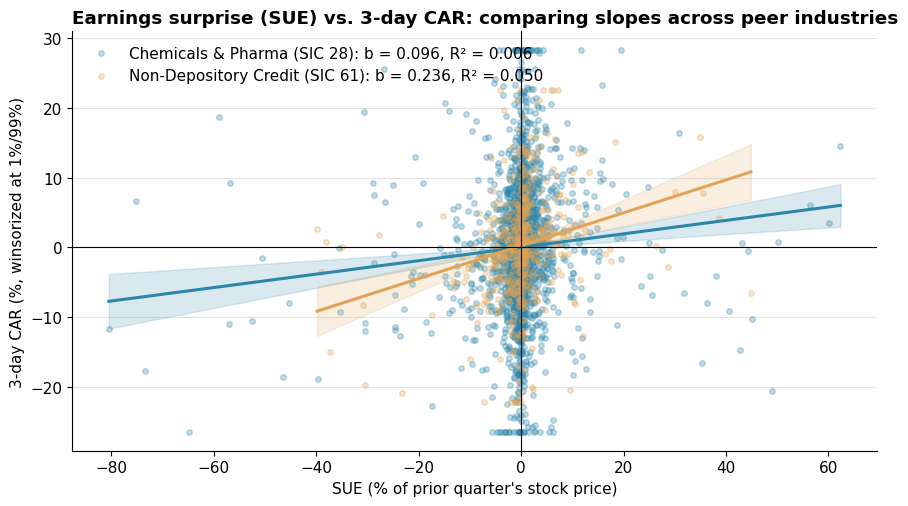

In [156]:
# Step 8. Figure 2: Scatter plot of SUE vs CAR (winsorized) with each industry's regression line (in-class w12 Part 4c)
fig, ax = plt.subplots(figsize=(9, 5.2))

for j, ind in enumerate(industries):
    df_ind = ind.events
    m_fit = smf.ols("car_w ~ sue", data=df_ind).fit()
    b_val = m_fit.params["sue"]
    r2_val = m_fit.rsquared

    # Plot scatter points for this industry
    ax.scatter(df_ind["sue"] * 100, df_ind["car_w"] * 100,
               s=16, alpha=0.30, color=colors[j],
               label=f"{ind.name} (SIC {ind.sic}): b = {b_val:.3f}, R² = {r2_val:.3f}")

    # Compute predicted regression line and 95% confidence band across industry's SUE range
    grid = pd.DataFrame({"sue": np.linspace(df_ind["sue"].min(), df_ind["sue"].max(), 100)})
    pred = m_fit.get_prediction(grid).summary_frame(alpha=0.05)

    ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                    color=colors[j], alpha=0.18)
    ax.plot(grid["sue"] * 100, pred["mean"] * 100, color=colors[j], linewidth=2.2)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Earnings surprise (SUE) vs. 3-day CAR: comparing slopes across peer industries",
             loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of prior quarter's stock price)")
ax.set_ylabel("3-day CAR (%, winsorized at 1%/99%)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figure2_peer_regression.png", dpi=200)
plt.show()

# Close WRDS connection at the end of the notebook
conn.close()